# Analisis EKG–PPG: Filtering, Estimasi Denyut, dan Resampling
**Mata kuliah:** Instrumentasi Medis — Teknik Fisika UGM · **Semester Ganjil 2026/2027**
**Nama / NIM:** *(isi)*
**Dataset:** BIDMC PPG and Respiration Dataset (PhysioNet) · **Library:** WFDB, MNE-Python, NeuroKit2

> Hasil pengolahan ini adalah informasi fisiologis, **bukan** diagnosis klinis.

**Daftar isi:** 0. Setup · 1. Akuisisi & metadata · 2. Pemeriksaan sinyal mentah · 3. Eksperimen 1 (filtering & PSD) · 4. Eksperimen 2 (BPM EKG vs PPG) · 5. Eksperimen 3 (sampling rate) · 6. Eksperimen pilihan A (PAT)

In [2]:
import os, warnings
from fractions import Fraction
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import resample_poly
import scipy, wfdb, mne
import neurokit2 as nk
try:
    from IPython.display import display
except ImportError:
    display = print

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

for m in (np, pd, matplotlib, scipy, wfdb, mne, nk):
    print(f"{m.__name__:12s} {m.__version__}")

numpy        2.1.2
pandas       2.2.3
matplotlib   3.9.2
scipy        1.14.1
wfdb         4.3.1
mne          1.13.2
neurokit2    0.3.0


## 1. Akuisisi data dan metadata
Data diambil dari https://physionet.org/content/bidmc/1.0.0/ dengan ID rekaman 35

In [3]:
RECORD = "bidmc35"          
PN_DIR = "bidmc/1.0.0"
SEG_START, SEG_DUR = 60, 60  # detik; segmen 60 s untuk Eksperimen 1 (filter dijalankan pada rekaman penuh)
WIN_S = 10                   # panjang jendela estimasi BPM (detik)

rec = wfdb.rdrecord(RECORD, pn_dir=PN_DIR)        # baca dataset
fs = int(rec.fs)                                  # dapatkan frekuensi sampling
names = [n.strip(" ,") for n in rec.sig_name]
units = [u.strip() for u in rec.units]

ecg_idx = names.index("II")
ppg_idx = names.index("PLETH")
ecg_raw = np.asarray(rec.p_signal[:, ecg_idx], dtype=float)
ppg_raw = np.asarray(rec.p_signal[:, ppg_idx], dtype=float)
assert not (np.isnan(ecg_raw).any() or np.isnan(ppg_raw).any()), "Ada NaN pada sinyal, tangani dahulu."

# Menampilkan item dari dataset beserta nilainya
meta = pd.DataFrame({
    "Item": ["ID rekaman", "Frekuensi sampling (Hz)", "Semua kanal", "Kanal EKG (satuan)",
             "Kanal PPG (satuan)", "Jumlah sampel", "Durasi (s)"],
    "Nilai": [RECORD, fs, ", ".join(names), f"{names[ecg_idx]} ({units[ecg_idx]})",
              f"{names[ppg_idx]} ({units[ppg_idx]})", len(ecg_raw), len(ecg_raw) / fs],
})
display(meta)

,Item,Nilai
0,ID rekaman,bidmc35
1,Frekuensi sampling (Hz),125
2,Semua kanal,"RESP, PLETH, II, V, AVR"
3,Kanal EKG (satuan),II (mV)
4,Kanal PPG (satuan),PLETH (NU)
5,Jumlah sampel,60001
6,Durasi (s),480.008


## 2. Pemeriksaan sinyal mentah dan kualitas
Pemeriksaan sederhana: NaN, rentang amplitudo, garis datar (flatline), dan polaritas EKG. Plot mentah memperlihatkan drift baseline, noise, dan artefak.

,Sinyal,Min,Maks,Std,Flatline (%)
0,EKG mentah,-0.498,1.5,0.2080,3.3017
1,PPG mentah,0.000,1.0,0.1608,2.7967


Skewness EKG mentah: 2.922


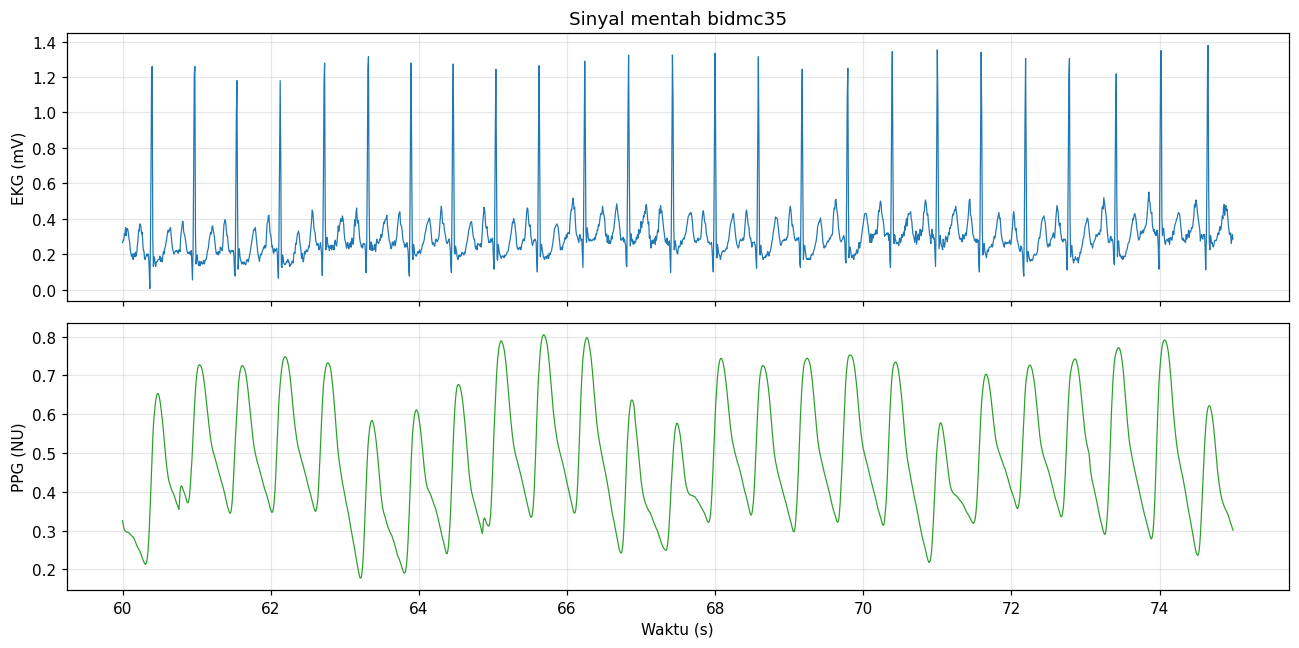

In [4]:
def quick_quality(x, label):
    return {"Sinyal": label, "Min": x.min(), "Maks": x.max(), "Std": x.std(),
            "Flatline (%)": 100 * np.mean(np.abs(np.diff(x)) < 1e-9)}

display(pd.DataFrame([quick_quality(ecg_raw, "EKG mentah"), quick_quality(ppg_raw, "PPG mentah")]).round(4))

# Heuristik polaritas: gelombang R yang dominan positif memberi skewness > 0
print("Skewness EKG mentah:", round(float(stats.skew(ecg_raw)), 3))
if stats.skew(ecg_raw) < 0:
    ecg_raw = -ecg_raw
    print("-> EKG tampak terbalik, polaritas dibalik (catat di laporan).")

t_all = np.arange(len(ecg_raw)) / fs
sl = slice(int(SEG_START * fs), int((SEG_START + SEG_DUR) * fs))
zoom = slice(int(SEG_START * fs), int((SEG_START + 15) * fs))

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(t_all[zoom], ecg_raw[zoom], lw=0.8); ax[0].set_ylabel(f"EKG ({units[ecg_idx]})")
ax[1].plot(t_all[zoom], ppg_raw[zoom], lw=0.8, color="tab:green"); ax[1].set_ylabel(f"PPG ({units[ppg_idx]})")
ax[1].set_xlabel("Waktu (s)"); ax[0].set_title(f"Sinyal mentah {RECORD}")
plt.tight_layout(); plt.savefig("figures/raw_signals.png", dpi=200); plt.show()

## 3. Eksperimen 1 — Pengaruh filtering
Tiga konfigurasi band-pass (A, B, C) diterapkan pada **rekaman penuh** (menghindari efek tepi), lalu dianalisis pada segmen 60 s. Detektor yang sama dipakai untuk semua konfigurasi agar perbedaan hanya berasal dari filter.

In [5]:
CFG = {
    "A": {"ecg": (0.5, 40), "ppg": (0.5, 8)},
    "B": {"ecg": (1, 30),   "ppg": (0.7, 5)},
    "C": {"ecg": (5, 20),   "ppg": (1, 3)},
}

def bp(x, lo, hi):
    return mne.filter.filter_data(x, sfreq=fs, l_freq=lo, h_freq=hi, verbose=False)

def detect_r(x, sr):
    _, info = nk.ecg_peaks(x, sampling_rate=sr, method="neurokit")
    return np.asarray(info["ECG_R_Peaks"], dtype=int)

def detect_ppg(x, sr):
    info = nk.ppg_findpeaks(x, sampling_rate=sr, method="elgendi")
    return np.asarray(info["PPG_Peaks"], dtype=int)

def peak_stats(pk, sr):
    if len(pk) < 2:
        return {"Puncak": len(pk), "BPM rata-rata": np.nan, "SD interval (ms)": np.nan, "Interval tak wajar": np.nan}
    d = np.diff(pk) / sr
    return {"Puncak": len(pk), "BPM rata-rata": 60 / d.mean(), "SD interval (ms)": d.std(ddof=1) * 1000,
            "Interval tak wajar": int(((d < 0.3) | (d > 2.0)).sum())}   # <0.3 s atau >2 s

filt, rows = {}, []

# Pembanding: tanpa filter
for kind, x, det in (("EKG", ecg_raw, detect_r), ("PPG", ppg_raw, detect_ppg)):
    try:
        pk = det(x[sl], fs)
        rows.append({"Konfigurasi": "Raw", "Sinyal": kind, "Band (Hz)": "-", **peak_stats(pk, fs)})
    except Exception as e:
        print(f"Deteksi {kind} raw gagal: {e}")
        rows.append({"Konfigurasi": "Raw", "Sinyal": kind, "Band (Hz)": "-", "Puncak": 0})

for name, c in CFG.items():
    e = bp(ecg_raw, *c["ecg"]); p = bp(ppg_raw, *c["ppg"])
    try:
        r = detect_r(e[sl], fs)
    except Exception as ex:
        print(f"[{name}] deteksi R gagal: {ex}"); r = np.array([], dtype=int)
    try:
        pk = detect_ppg(p[sl], fs)
    except Exception as ex:
        print(f"[{name}] deteksi PPG gagal: {ex}"); pk = np.array([], dtype=int)
    filt[name] = {"ecg": e, "ppg": p, "r": r, "p": pk}
    rows.append({"Konfigurasi": name, "Sinyal": "EKG", "Band (Hz)": f"{c['ecg'][0]}–{c['ecg'][1]}", **peak_stats(r, fs)})
    rows.append({"Konfigurasi": name, "Sinyal": "PPG", "Band (Hz)": f"{c['ppg'][0]}–{c['ppg'][1]}", **peak_stats(pk, fs)})

tab_exp1 = pd.DataFrame(rows)
display(tab_exp1.round(2))

,Konfigurasi,Sinyal,Band (Hz),Puncak,BPM rata-rata,SD interval (ms),Interval tak wajar
0,Raw,EKG,-,100,100.18,20.81,0
1,Raw,PPG,-,100,100.15,25.30,0
2,A,EKG,0.5–40,100,100.16,20.96,0
3,A,PPG,0.5–8,100,100.13,26.91,0
4,B,EKG,1–30,100,100.16,20.39,0
5,B,PPG,0.7–5,100,100.15,22.28,0
6,C,EKG,5–20,100,100.16,20.26,0
7,C,PPG,1–3,100,100.15,20.63,0


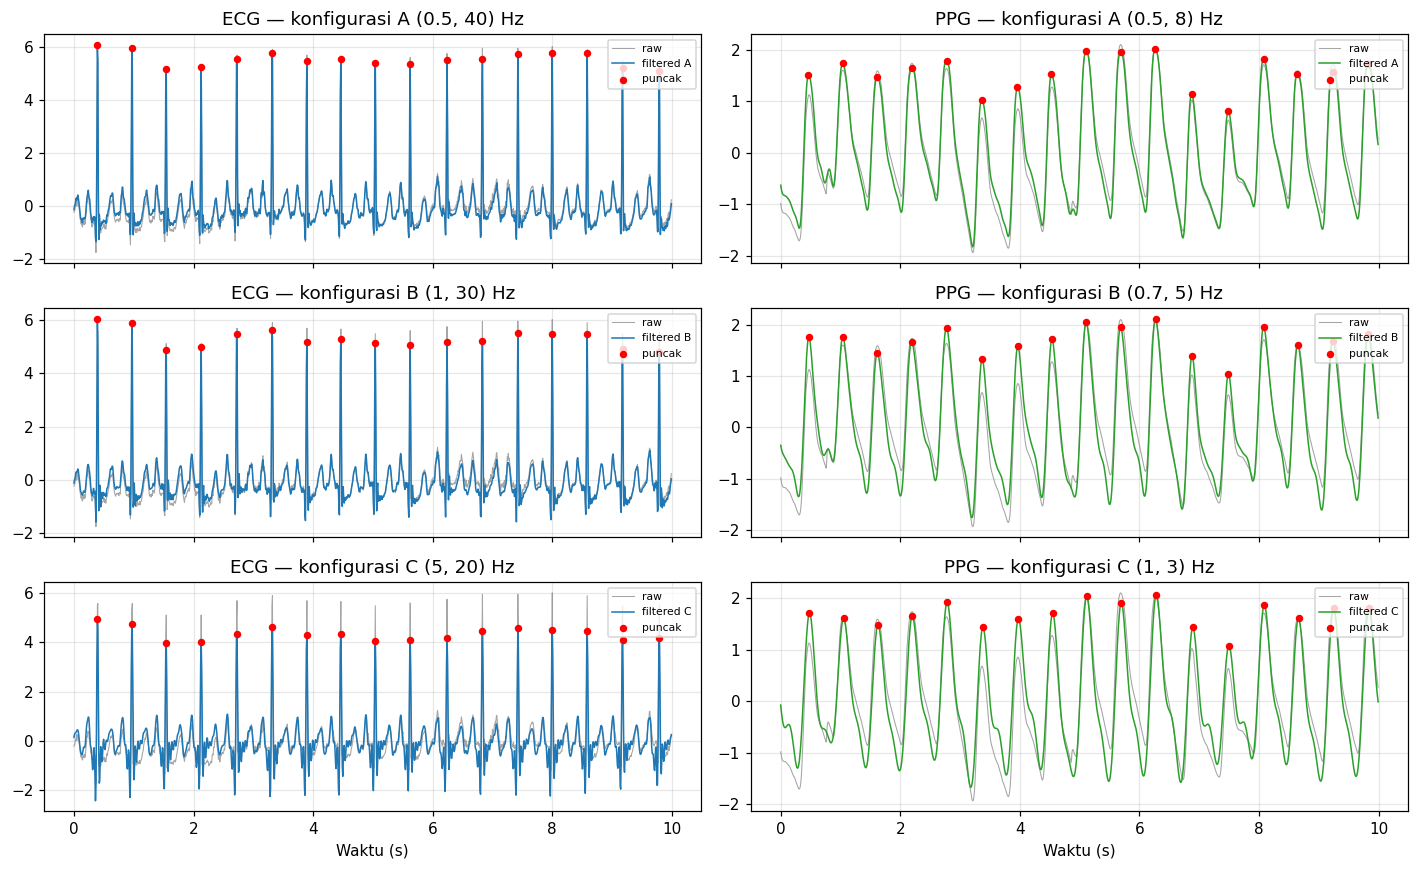

In [6]:
# Grafik raw vs filtered (10 detik pertama segmen), z-score agar dapat dibandingkan bentuknya
z = lambda x: (x - x.mean()) / x.std()
n10 = 10 * fs
tt = np.arange(n10) / fs
fig, ax = plt.subplots(3, 2, figsize=(13, 8), sharex=True)
for i, name in enumerate(CFG):
    for j, (key, raw, pk_key, col) in enumerate((("ecg", ecg_raw, "r", "tab:blue"), ("ppg", ppg_raw, "p", "tab:green"))):
        xr = z(raw[sl][:n10]); xf = z(filt[name][key][sl][:n10])
        ax[i, j].plot(tt, xr, color="gray", lw=0.7, alpha=0.7, label="raw")
        ax[i, j].plot(tt, xf, color=col, lw=1.0, label=f"filtered {name}")
        pk = filt[name][pk_key]; pk = pk[pk < n10]
        ax[i, j].scatter(pk / fs, xf[pk], color="red", s=15, zorder=3, label="puncak")
        ax[i, j].set_title(f"{key.upper()} — konfigurasi {name} {CFG[name][key]} Hz")
        ax[i, j].legend(loc="upper right", fontsize=7)
ax[2, 0].set_xlabel("Waktu (s)"); ax[2, 1].set_xlabel("Waktu (s)")
plt.tight_layout(); plt.savefig("figures/filtered_signals.png", dpi=200); plt.show()

### A. Analisis Jumlah Puncak
Berdasarkan grafik diatas, tidak ada konfigurasi yang mengalami kehilangan maupun penambahan puncak palsu. Dapat diketahui bahwa seluruh konfigurasi medeteksi 17 siklus denyut secara konsisten.
Meskipun demikian terdapat penurunan tajam pada tinggi puncak R-peak EKG di konfigurasi c, yang disebabkan oleh terpotongnya komponen energi frekuensi tinggi kompleks QRS. Pada sinyal dengan SNR lebih rendah, penurunan amplitudo ini berpotensi menyebabkan algoritma gagal mendeteksi puncak. 
### B. Pergeseran Puncak PPG terhadap Respons Fase dan Orde Filter
Berdasarkan grafik hasil plot, dapat disimpulkan bahwa filter makin dibutuhkan pada pita frekuensi yang sempit (konfigurasi c), terutama filter dengan orde yang lebih tinggi. Hal ini dikarenakan filter yang memiliki orde tinggi menghasilkan transisi potongan (*roll-off*) yang curam, yang diakibatkan oleh meningkatnya waktu tunda grup (*group delay*) dan besarnya dispersi fase antar komponen frekuensi

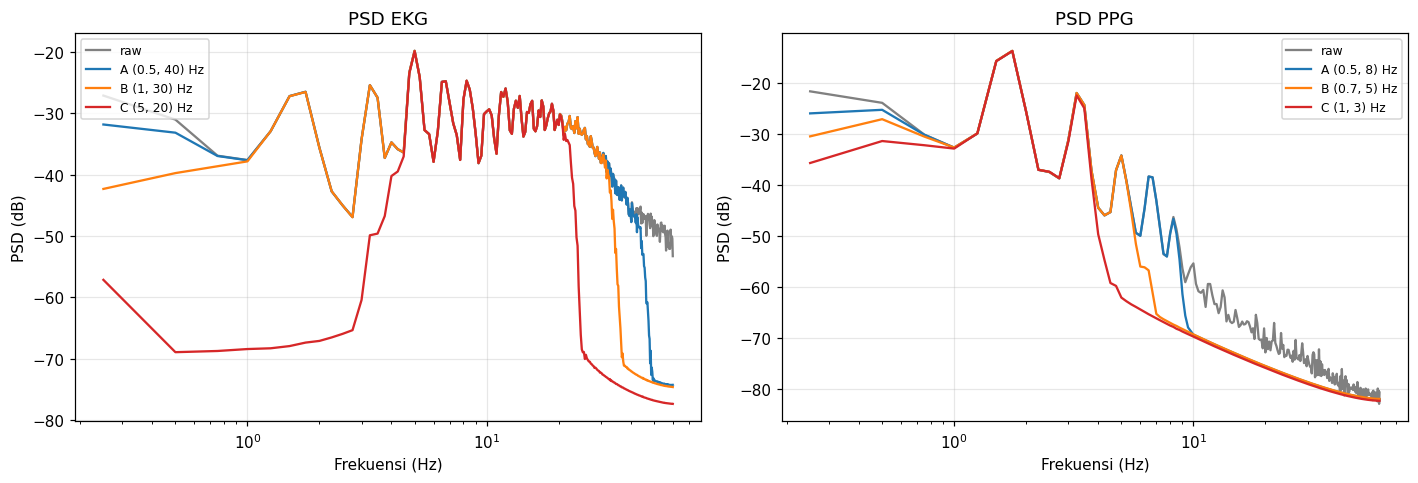

In [7]:
# PSD (Welch) raw vs filtered pada segmen 60 s
from mne.time_frequency import psd_array_welch

def psd_db(x):
    p, f = psd_array_welch(x[sl], sfreq=fs, fmin=0.05, fmax=60, n_fft=4 * fs, verbose=False)
    return f, 10 * np.log10(np.squeeze(p) + 1e-20)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for j, (key, raw, title) in enumerate((("ecg", ecg_raw, "EKG"), ("ppg", ppg_raw, "PPG"))):
    f, p = psd_db(raw); ax[j].plot(f, p, color="gray", label="raw")
    for name, col in zip(CFG, ("tab:blue", "tab:orange", "tab:red")):
        f, p = psd_db(filt[name][key]); ax[j].plot(f, p, color=col, label=f"{name} {CFG[name][key]} Hz")
    ax[j].set_title(f"PSD {title}"); ax[j].set_xlabel("Frekuensi (Hz)"); ax[j].set_ylabel("PSD (dB)")
    ax[j].set_xscale("log"); ax[j].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/psd_comparison.png", dpi=200); plt.show()

### c. Kaitan Kurva PSD dengan Komponen yang Dibuang
#### - Drift Baseline ($< 0,5\text{ Hz}$)
Pada kurva raw (abu-abu), daya spektral cukup tinggi di area $<0,5\text{ Hz}$ akibat artefak pernapasan dan pergerakan elektroda/sensor. Konfigurasi A ($0,5\text{ Hz}$), B ($0,7\text{--}1\text{ Hz}$), dan terutama C ($1\text{--}5\text{ Hz}$) menekan daya pada wilayah ini hingga turun ke $-35\text{ dB}$ (PPG) dan $-60\text{ hingga }-70\text{ dB}$ (EKG), sehingga garis dasar sinyal kembali rata di nol
#### - Harmonik QRS & Harmonik PPG
Pada PSD EKG, energi kompleks QRS terdistrbusi lebar dari sekitar 4 Hz hingga 30-40 Hz. Konfigurasi C memotong tajam di atas 20 Hz, membuang harmonik atas QRS sehingga puncak R pada domain waktu menjadi tumpul sehingga amplitudonya turun. 
Pada PSD PPG, frekuensi denyut jantung dan harmonik kedua tampak dominan. Harmonik kedua dan ketiga dibuang karena konfigurasi C memotong tepat di 3 Hz. 

## 4. Eksperimen 2 — Perbandingan heart rate EKG dan PPG
Konfigurasi A dipakai pada seluruh rekaman. BPM dihitung per jendela 10 s non-overlap: 
$$
HR = 60/\overline{\text{interval}}
$$
Jendela dengan puncak kurang dari `MIN_PEAKS` **tidak** dihitung, tetapi tetap dicatat beserta alasannya.

In [8]:
MIN_PEAKS = 4   # minimal puncak per jendela (=> minimal 3 interval)

e_A, p_A = filt["A"]["ecg"], filt["A"]["ppg"]
r_all = detect_r(e_A, fs)
p_all = detect_ppg(p_A, fs)
print(f"Puncak R terdeteksi: {len(r_all)} | Puncak sistolik PPG: {len(p_all)}")

def window_hr(peaks, sr, n_samples, win_s=WIN_S, min_peaks=MIN_PEAKS):
    w = int(win_s * sr); out = []
    for k in range(n_samples // w):
        a, b = k * w, (k + 1) * w
        pk = peaks[(peaks >= a) & (peaks < b)]
        hr = 60 / np.mean(np.diff(pk) / sr) if len(pk) >= min_peaks else np.nan
        out.append((k, a / sr, len(pk), hr))
    return pd.DataFrame(out, columns=["k", "t_mulai", "n", "hr"])

we = window_hr(r_all, fs, len(e_A)); wp = window_hr(p_all, fs, len(p_A))
tab2 = pd.DataFrame({
    "Jendela": we.k, "Mulai (s)": we.t_mulai,
    "n_R": we.n, "n_PPG": wp.n,
    "HR_EKG": we.hr, "HR_PPG": wp.hr,
})
tab2["Error (PPG−EKG)"] = tab2.HR_PPG - tab2.HR_EKG
tab2["|Error|"] = tab2["Error (PPG−EKG)"].abs()
tab2["Selisih jumlah puncak"] = tab2.n_PPG - tab2.n_R
tab2["Status"] = np.where(tab2[["HR_EKG", "HR_PPG"]].isna().any(axis=1), "DIKECUALIKAN (puncak kurang)", "valid")
display(tab2.round(2))

valid = tab2[tab2.Status == "valid"]
N = len(valid)
MAE = valid["|Error|"].mean()
bias = valid["Error (PPG−EKG)"].mean()
rmse = np.sqrt((valid["Error (PPG−EKG)"] ** 2).mean())
print(f"Jendela valid: {N}/{len(tab2)} | MAE = {MAE:.3f} BPM | bias = {bias:+.3f} BPM | RMSE = {rmse:.3f} BPM | maks |err| = {valid['|Error|'].max():.2f} BPM")
print("Jendela dengan selisih jumlah puncak != 0 :",
      tab2.loc[tab2["Selisih jumlah puncak"] != 0, "Jendela"].tolist())

Puncak R terdeteksi: 810 | Puncak sistolik PPG: 778


,Jendela,Mulai (s),n_R,n_PPG,HR_EKG,HR_PPG,Error (PPG−EKG),|Error|,Selisih jumlah puncak,Status
0,0,0.0,17,16,101.95,102.18,0.23,0.23,-1,valid
1,1,10.0,17,17,102.65,101.61,-1.04,1.04,0,valid
2,2,20.0,17,18,106.76,106.78,0.02,0.02,1,valid
3,3,30.0,17,15,106.10,87.21,-18.89,18.89,-2,valid
4,4,40.0,15,13,91.15,75.06,-16.08,16.08,-2,valid
5,5,50.0,18,17,108.51,102.74,-5.77,5.77,-1,valid
6,6,60.0,17,17,102.13,102.56,0.44,0.44,0,valid
7,7,70.0,17,16,100.59,99.65,-0.94,0.94,-1,valid
8,8,80.0,17,18,102.48,102.74,0.26,0.26,1,valid
9,9,90.0,16,16,97.74,97.83,0.08,0.08,0,valid


Jendela valid: 48/48 | MAE = 4.429 BPM | bias = -4.205 BPM | RMSE = 10.890 BPM | maks |err| = 57.06 BPM
Jendela dengan selisih jumlah puncak != 0 : [0, 2, 3, 4, 5, 7, 8, 17, 19, 21, 25, 29, 31, 38, 39, 41, 45, 46, 47]


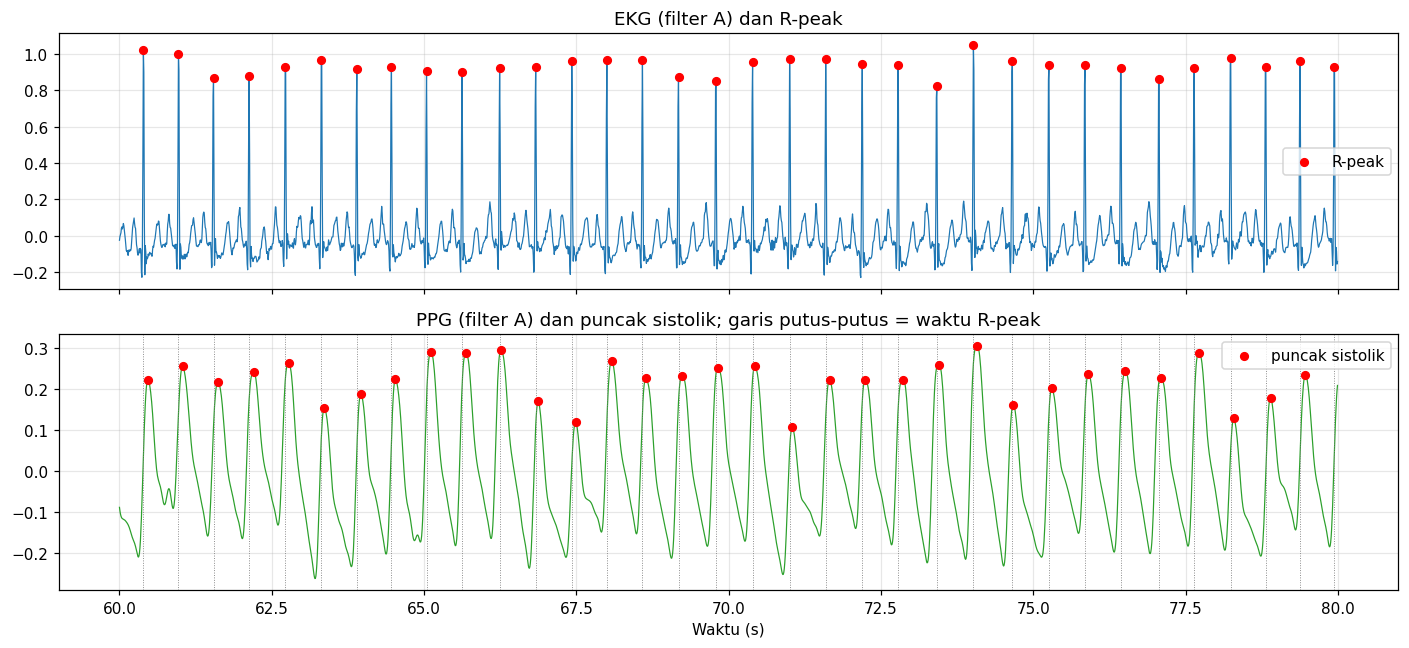

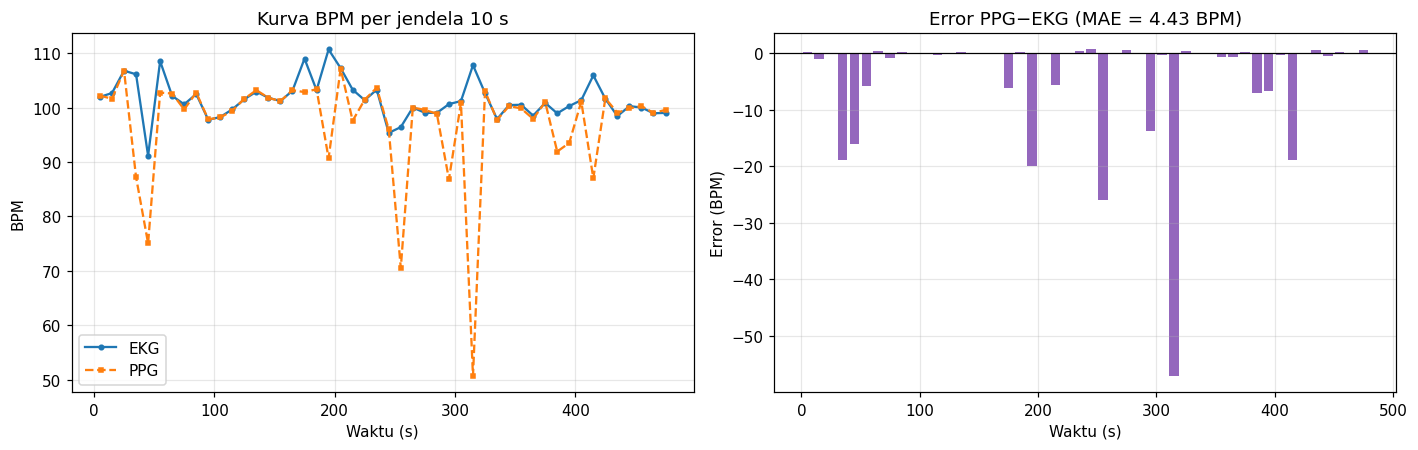

In [14]:
# Grafik anotasi puncak (20 s) — ubah T0 untuk memeriksa jendela lain
T0 = 60
a, b = int(T0 * fs), int((T0 + 20) * fs)
tt = np.arange(a, b) / fs
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].plot(tt, e_A[a:b], lw=0.8)
rr = r_all[(r_all >= a) & (r_all < b)]; ax[0].scatter(rr / fs, e_A[rr], color="red", s=25, label="R-peak", zorder=3)
ax[1].plot(tt, p_A[a:b], lw=0.8, color="tab:green")
pp = p_all[(p_all >= a) & (p_all < b)]; ax[1].scatter(pp / fs, p_A[pp], color="red", s=25, label="puncak sistolik", zorder=3)
for x in rr / fs: ax[1].axvline(x, color="gray", ls=":", lw=0.6)
ax[0].set_title("EKG (filter A) dan R-peak"); ax[1].set_title("PPG (filter A) dan puncak sistolik; garis putus-putus = waktu R-peak")
ax[1].set_xlabel("Waktu (s)"); ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/peak_detection.png", dpi=200); plt.show()

# Kurva BPM dan error
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
tm = tab2["Mulai (s)"] + WIN_S / 2
ax[0].plot(tm, tab2.HR_EKG, "o-", ms=3, label="EKG"); ax[0].plot(tm, tab2.HR_PPG, "s--", ms=3, label="PPG")
ax[0].set_xlabel("Waktu (s)"); ax[0].set_ylabel("BPM"); ax[0].set_title("Kurva BPM per jendela 10 s"); ax[0].legend()
ax[1].bar(tm, tab2["Error (PPG−EKG)"], width=WIN_S * 0.8, color="tab:purple")
ax[1].axhline(0, color="k", lw=0.8); ax[1].set_xlabel("Waktu (s)"); ax[1].set_ylabel("Error (BPM)")
ax[1].set_title(f"Error PPG−EKG (MAE = {MAE:.2f} BPM)")
plt.tight_layout(); plt.savefig("figures/error_analysis.png", dpi=200); plt.show()

### A. Besaran MAE, Bias, dan Persebaran Error
Magnitudo MAE dan bias yang hampir sama menunjukkan bahwa error bersifat sistematis ke arah negatif (underestimation PPG terhadap EKG). Pola error tidak merata melainkan terpusat pada lonjakan di jendela tertentu(misalnya sekitar $t = 30\text{--}50\text{ s}$, $190\text{ s}$,), sedangkan di luar segmen tersebut kurva BPM berimpit mendekati nol. Lonjakan negatif ekstrim terjadi karena puncak sistolik PPG hilang karena artefak gerakan atau penurunan amplitudo sinyal
### B. Analisis Jendela dengan Selisih Jumlah Puncak $\neq 0$
Terdapat 19 dari 48 jendela yang memiliki jumlah puncak berbeda, namun pada beberapa jendela nilai BPM-nya tetap terlihat hampir sama. Hal ini dikarenakan adanya jeda waktu rambat gelombang nadi (Pulse Arrival Time) membuat puncak PPG selalu muncul terlambat terhadap R-peak EKG. Akibatnya, detak di ujung batas jendela $10\text{ s}$ sering terhitung di dua jendela bersebelahan (boundary effect). Selain itu, kombinasi puncak hilang dan puncak ganda (double peak dari dicrotic notch) juga dapat saling mengompensasi rata-rata interval, sehingga BPM yang mirip tidak menjamin seluruh puncak terdeteksi benar.


## 5. Eksperimen 3 — Pengaruh frekuensi sampling
Sinyal berfilter A di-*resample* ke 100, 50, dan 25 Hz dengan `scipy.signal.resample_poly` (sudah berisi low-pass anti-aliasing). Detektor NeuroKit2 menerima `sampling_rate` baru; parameter internalnya dalam satuan detik sehingga ikut menyesuaikan. **Acuan** = puncak pada frekuensi asli. Puncak dianggap cocok bila selisih waktu ≤ 100 ms.

In [10]:
TARGETS = [fs, 100, 50, 25]
TOL = 0.100  # s

def resample_to(x, target):
    fr = Fraction(target, fs).limit_denominator(1000)
    return resample_poly(x, fr.numerator, fr.denominator)

def match_times(ref_t, test_t, tol=TOL):
    if len(test_t) == 0:
        return np.array([]), 0, len(ref_t), 0
    i = np.searchsorted(test_t, ref_t)
    il, ir = np.clip(i - 1, 0, len(test_t) - 1), np.clip(i, 0, len(test_t) - 1)
    nearest = np.where(np.abs(test_t[il] - ref_t) <= np.abs(test_t[ir] - ref_t), il, ir)
    err = test_t[nearest] - ref_t
    ok = np.abs(err) <= tol
    matched = int(ok.sum())
    extra = len(test_t) - np.unique(nearest[ok]).size
    return err[ok], matched, len(ref_t) - matched, extra

ref = {"EKG": r_all / fs, "PPG": p_all / fs}
ref_win = {"EKG": we, "PPG": wp}
sig = {"EKG": (e_A, detect_r), "PPG": (p_A, detect_ppg)}

rows3, store3 = [], {}
for kind, (x, det) in sig.items():
    for tgt in TARGETS:
        if tgt > fs:
            print(f"Lewati {tgt} Hz (> fs asli)"); continue
        xr = x if tgt == fs else resample_to(x, tgt)
        pk = det(xr, tgt)
        err, matched, missed, extra = match_times(ref[kind], pk / tgt)
        w = window_hr(pk, tgt, len(xr))
        n = min(len(w), len(ref_win[kind]))
        d = (w.hr.values[:n] - ref_win[kind].hr.values[:n])
        store3[(kind, tgt)] = (xr, pk)
        rows3.append({
            "Sinyal": kind, "fs (Hz)": tgt, "Resolusi 1/fs (ms)": 1000 / tgt,
            "Puncak": len(pk), "Cocok": matched, "Terlewat": missed, "Ekstra": extra,
            "MAE waktu (ms)": 1000 * np.mean(np.abs(err)) if len(err) else np.nan,
            "Bias waktu (ms)": 1000 * np.mean(err) if len(err) else np.nan,
            "Maks |err| (ms)": 1000 * np.max(np.abs(err)) if len(err) else np.nan,
            "MAE BPM vs asli": np.nanmean(np.abs(d)) if np.isfinite(d).any() else np.nan,
        })
tab3 = pd.DataFrame(rows3)
display(tab3.round(2))

,Sinyal,fs (Hz),Resolusi 1/fs (ms),Puncak,Cocok,Terlewat,Ekstra,MAE waktu (ms),Bias waktu (ms),Maks |err| (ms),MAE BPM vs asli
0,EKG,125,8.0,810,810,0,0,0.00,0.00,0.0,0.00
1,EKG,100,10.0,810,810,0,0,3.33,-0.29,8.0,0.06
2,EKG,50,20.0,809,809,1,0,5.44,-0.53,12.0,0.22
3,EKG,25,40.0,666,666,144,0,9.15,-1.49,24.0,17.49
4,PPG,125,8.0,778,778,0,0,0.00,0.00,0.0,0.00
5,PPG,100,10.0,779,778,0,1,2.96,-0.03,8.0,0.17
6,PPG,50,20.0,779,778,0,1,5.02,-0.17,12.0,0.21
7,PPG,25,40.0,747,742,36,5,9.81,0.37,24.0,3.48


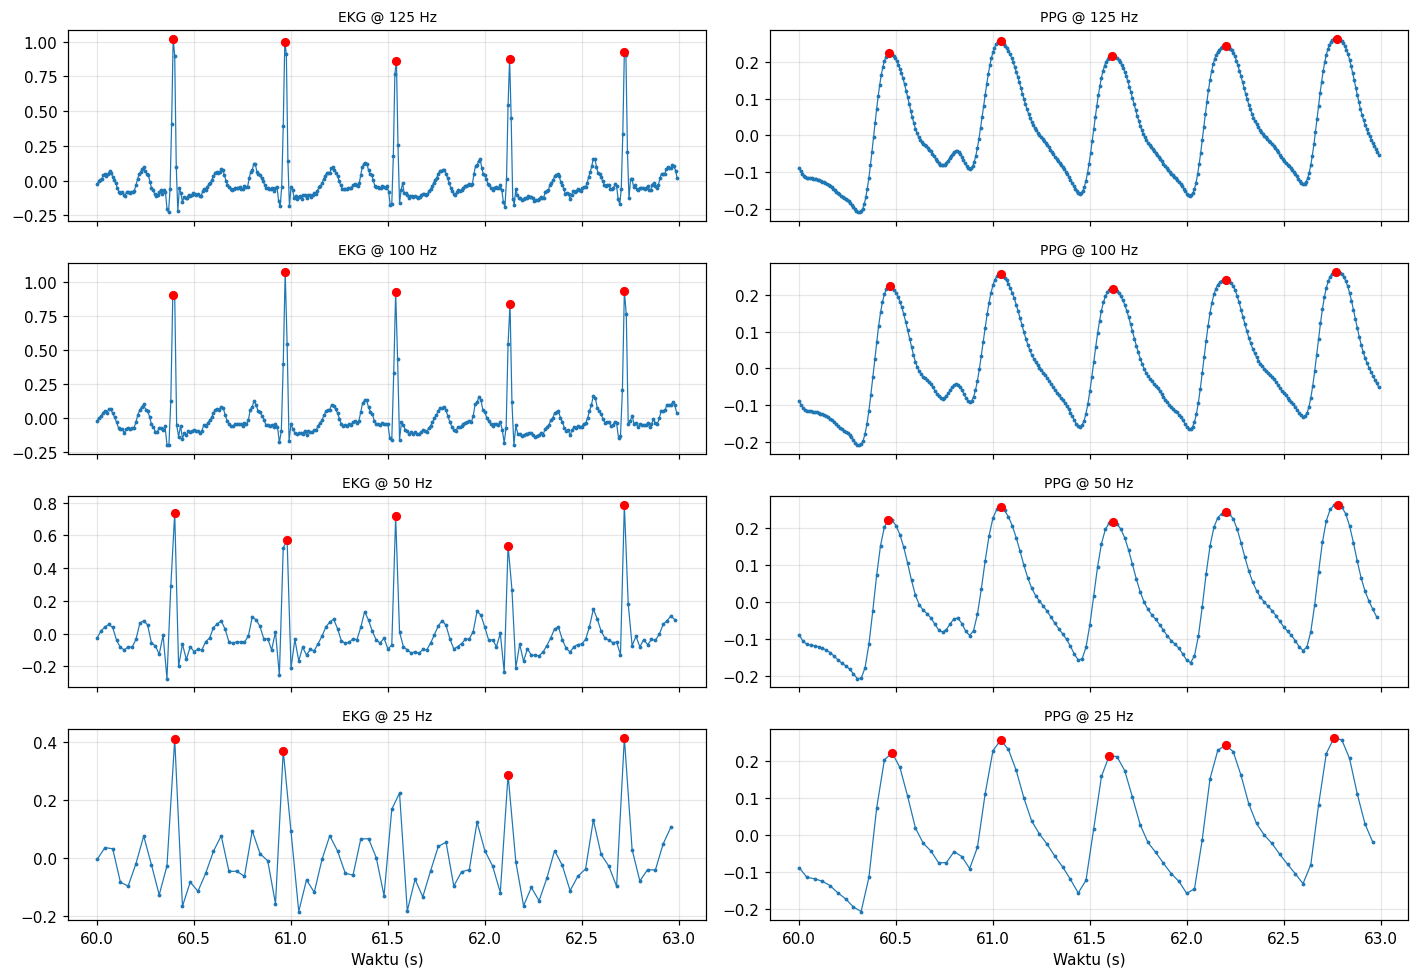

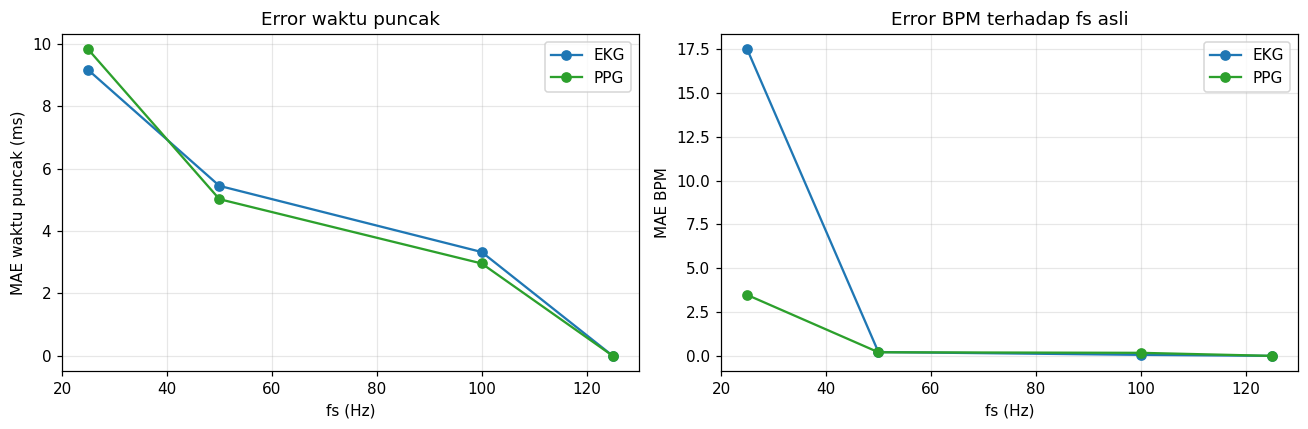

In [11]:
# Grafik hasil resampling (3 detik) dan error waktu puncak
a0 = 60
fig, ax = plt.subplots(len(TARGETS), 2, figsize=(13, 9), sharex=True)
for i, tgt in enumerate(TARGETS):
    for j, kind in enumerate(("EKG", "PPG")):
        if (kind, tgt) not in store3: continue
        xr, pk = store3[(kind, tgt)]
        s, e = int(a0 * tgt), int((a0 + 3) * tgt)
        tt = np.arange(s, e) / tgt
        ax[i, j].plot(tt, xr[s:e], ".-", ms=3, lw=0.8)
        q = pk[(pk >= s) & (pk < e)]
        ax[i, j].scatter(q / tgt, xr[q], color="red", s=25, zorder=3)
        ax[i, j].set_title(f"{kind} @ {tgt} Hz", fontsize=9)
ax[-1, 0].set_xlabel("Waktu (s)"); ax[-1, 1].set_xlabel("Waktu (s)")
plt.tight_layout(); plt.savefig("figures/resampling.png", dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for kind, col in (("EKG", "tab:blue"), ("PPG", "tab:green")):
    d = tab3[tab3.Sinyal == kind]
    ax[0].plot(d["fs (Hz)"], d["MAE waktu (ms)"], "o-", color=col, label=kind)
    ax[1].plot(d["fs (Hz)"], d["MAE BPM vs asli"], "o-", color=col, label=kind)
ax[0].set_xlabel("fs (Hz)"); ax[0].set_ylabel("MAE waktu puncak (ms)"); ax[0].set_title("Error waktu puncak"); ax[0].legend()
ax[1].set_xlabel("fs (Hz)"); ax[1].set_ylabel("MAE BPM"); ax[1].set_title("Error BPM terhadap fs asli"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/resampling_error.png", dpi=200); plt.show()

#### A. Perbandingan MAE Waktu Puncak dengan Resolusi Teoretis ($1/f_s$)
secara teoritis, rata-rata nilai mutlak dari galat kuantisasi seragam. Nilai MAE waktu hasil eksperimen (sekitar 3 ms, 5 ms, dan 9-10 ms) sesuai dengan batas resolusi teroitis karena seluruh nilainya berada di bawah batas galat kuantisasi maksimum dan mengikuti tren eksponensial terbalik terhadap kenaiakan $f_s$ 
#### B. Sensitivitas Penurunan $f_s$
EKG jauh lebih sensitif terhadap penurunan frekuensi sampling dibandingkan PPG, terutama pada $f_s < 50\text{ Hz}$. Hal ini dikarenakan kompleks QRS pada EKG merupakan impuls yang sangat sempit dan tajam. Ketika $f_s$ diturukan ke 25 Hz, filter *anti-aliasing* memotong seluruh spektrum di atas 12,5 Hz. Ini mengakibatkan puncak R kehilangan ketajaman dan amplitudonya anjlok drastis. Sebaliknya, gelombang PPG bersifat halus dengna frekuensi dominan rendah (1-5 Hz), sehingga berada jauh di bawah batas Nyquist 12,5 Hz. Penurunan $f_s$ hampir tidak mengubah amplitudo maupun bentuk dasar puncak sistolik PPG
#### C. Puncak Terlewat pada 25 Hz
Pada EKG, terjadi puncak yang terlewat pada sekitar 61,55 s karena amplitudo puncak R teredeam dengan gelombang T sehingga gagal dideteksi algoritma. Hilangnya puncak R menggandakan interval RR, menyebabkan error BPM EKG melonjak tajam. Puncak yang terlewat ini akan sangat merusak akuras HRV. Hal ini dikarenakan gabungan galat kuantisasi waktu  ($\pm 20\text{ ms}$) dan lonjakan interval $\text{RR}$ artifisial akibat puncak yang terlewat mendistorsi metrik variabilitas detak jantung.


## 6. Eksperimen pilihan A — Pulse Arrival Time (PAT)
PAT = selang waktu dari R-peak EKG ke titik karakteristik PPG pada beat yang sama. Tiga titik dibandingkan: *foot* (minimum), *maximum slope*, dan puncak sistolik. Pasangan dibentuk dengan mencari puncak PPG pertama dalam 0,1–0,6 s setelah R-peak; R-peak tanpa pasangan **dilaporkan**, tidak dihapus diam-diam.

R-peak total: 810 | berpasangan: 136 | tanpa pasangan: 674


,n,Rata-rata (ms),SD (ms),Min (ms),Maks (ms)
foot,136.0,5.1,38.5,0.0,360.0
max slope,136.0,23.8,61.6,0.0,424.0
puncak sistolik,136.0,134.7,68.8,104.0,576.0


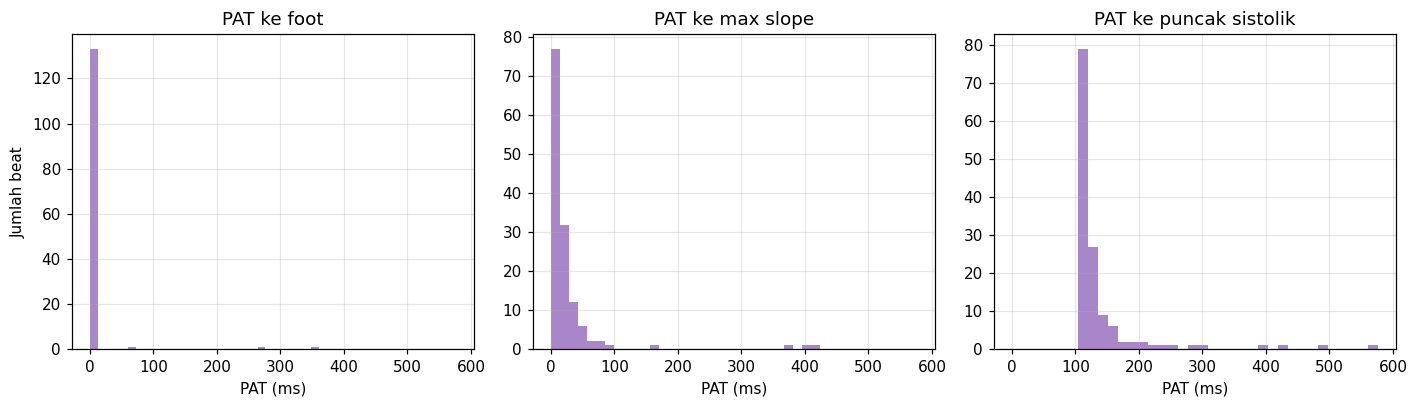

In [12]:
d_ppg = np.gradient(p_A, 1 / fs)
pat = {"foot": [], "max slope": [], "puncak sistolik": []}
unpaired = 0
for ri in r_all:
    cand = p_all[(p_all > ri + 0.1 * fs) & (p_all < ri + 0.6 * fs)]
    if len(cand) == 0:
        unpaired += 1; continue
    pi = int(cand[0])
    seg = slice(ri, pi + 1)
    pat["foot"].append((ri + np.argmin(p_A[seg]) - ri) / fs)
    pat["max slope"].append((ri + np.argmax(d_ppg[seg]) - ri) / fs)
    pat["puncak sistolik"].append((pi - ri) / fs)

print(f"R-peak total: {len(r_all)} | berpasangan: {len(pat['foot'])} | tanpa pasangan: {unpaired}")
tab_pat = pd.DataFrame({k: {"n": len(v), "Rata-rata (ms)": 1000 * np.mean(v), "SD (ms)": 1000 * np.std(v, ddof=1),
                            "Min (ms)": 1000 * np.min(v), "Maks (ms)": 1000 * np.max(v)} for k, v in pat.items()}).T
display(tab_pat.round(1))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True)
for a_, (k, v) in zip(ax, pat.items()):
    a_.hist(1000 * np.array(v), bins=30, color="tab:purple", alpha=0.8)
    a_.set_title(f"PAT ke {k}"); a_.set_xlabel("PAT (ms)")
ax[0].set_ylabel("Jumlah beat")
plt.tight_layout(); plt.savefig("figures/pat_distribution.png", dpi=200); plt.show()

#### A. Sebaran PAT Antar Titik Karakteristik dan Faktor yang Memengaruhinya
Berdasarkan histogram, sebaran nilai $\text{PAT}$ semakin melebar (right-skewed) dan bergeser ke nilai waktu yang lebih besar seiring perpindahan titik acuan dari foot ($\sim 0\text{--}15\text{ ms}$), max slope ($\sim 0\text{--}60\text{ ms}$), hingga puncak sistolik ($\sim 100\text{--}200\text{ ms}$). Secara fisiologis, variasi dan ekor distribusi (outlier hingga $>300\text{ ms}$) ini dipengaruhi oleh perubahan tekanan darah dan kekakuan arteri (arteri yang kaku mempercepat rambat gelombang sehingga $\text{PAT}$ memendek), modulasi siklus respirasi yang memengaruhi aliran balik vena dan variasi $\text{PEP}$, serta panjang lintasan vaskular menuju lokasi sensor PPG (misalnya jari vs telinga) dan refleksi gelombang perifer yang menggeser posisi puncak sistolik.   
#### B. Batasan Pasangan Beat pada Detak Jantung (HR) Tinggi
Penentuan pasangan R-peak dan puncak PPG menggunakan jendela pencarian tetap (misalnya $0,1\text{--}0,6\text{ s}$) memiliki batasan serius ketika Heart Rate (HR) subjek meningkat tinggi. Pada $\text{HR} > 100\text{--}120\text{ BPM}$, interval antar-detak ($\text{RR}$) menyempit menjadi kurang dari $0,5\text{--}0,6\text{ s}$, sehingga batas atas jendela pencarian ($0,6\text{ s}$) melampaui siklus detak berikutnya dan berisiko memasangkan R-peak dengan puncak PPG dari siklus jantung selanjutnya. Sebaliknya, apabila $\text{PAT}$ aktual sangat pendek (seperti pada titik foot atau max slope yang bernilai $< 100\text{ ms}$ atau $0,1\text{ s}$ pada grafik), batas bawah $0,1\text{ s}$ dapat memotong distribusi valid sehingga algoritma gagal memasangkan detak yang benar

## Checklist sebelum dikumpulkan
- [ ] `Kernel → Restart & Run All` berjalan tanpa error
- [ ] `RECORD`, nama, dan NIM sudah diisi; semua catatan interpretasi sudah dilengkapi
- [ ] 5 berkas wajib di `figures/` tersedia (`raw_signals`, `filtered_signals`, `psd_comparison`, `peak_detection`, `error_analysis`)
- [ ] Versi library, parameter, dan batasan dicatat di README dan laporan